In [71]:
import sys
import os
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

#import pynwb
import h5py

from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../import'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils

In [72]:
path = os.path.join(os.path.expanduser('~'), '/home/julian-zim/Desktop/DATA/fly-2023-schaffner/markers')			# path to nbw file folder
# file_ids, filenames, traces, ball_motions, behavioral_states = read_utils.get_data(path)

In [73]:
def print_structure(name, _):
	print(name)
def get_hdf5_files(path):
	filenames = sorted(os.listdir(path))
	return [h5py.File(os.path.join(path, filename), 'r') for filename in filenames]

raw_files = get_hdf5_files(path)
for raw_file in raw_files:
	print('================ FILENAME', raw_file.filename)
	raw_file.visititems(print_structure)

================ FILENAME /home/julian-zim/Desktop/DATA/fly-2023-schaffner/markers/2019_06_26_fly2.h5
df_with_missing
df_with_missing/_i_table
df_with_missing/_i_table/index
df_with_missing/_i_table/index/abounds
df_with_missing/_i_table/index/bounds
df_with_missing/_i_table/index/indices
df_with_missing/_i_table/index/indicesLR
df_with_missing/_i_table/index/mbounds
df_with_missing/_i_table/index/mranges
df_with_missing/_i_table/index/ranges
df_with_missing/_i_table/index/sorted
df_with_missing/_i_table/index/sortedLR
df_with_missing/_i_table/index/zbounds
df_with_missing/table
================ FILENAME /home/julian-zim/Desktop/DATA/fly-2023-schaffner/markers/2019_08_07_fly2.h5
df_with_missing
df_with_missing/_i_table
df_with_missing/_i_table/index
df_with_missing/_i_table/index/abounds
df_with_missing/_i_table/index/bounds
df_with_missing/_i_table/index/indices
df_with_missing/_i_table/index/indicesLR
df_with_missing/_i_table/index/mbounds
df_with_missing/_i_table/index/mranges
df_wi

In [74]:
datasindices = list()
for raw_file in raw_files:
	print('================ FILENAME', raw_file.filename)
	for key in raw_file['df_with_missing/_i_table/index']:
		datasindices.append(raw_file['df_with_missing/_i_table/index'][key][:])

================ FILENAME /home/julian-zim/Desktop/DATA/fly-2023-schaffner/markers/2019_06_26_fly2.h5
================ FILENAME /home/julian-zim/Desktop/DATA/fly-2023-schaffner/markers/2019_08_07_fly2.h5


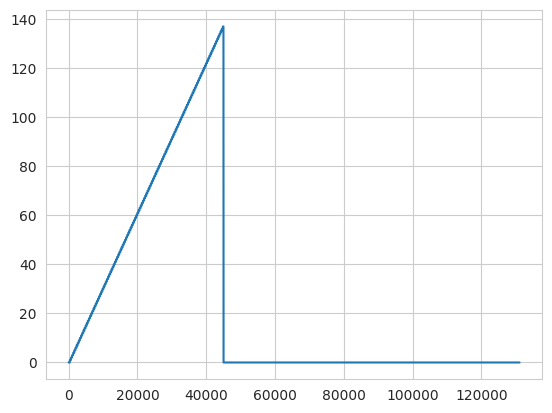

In [75]:
plt.plot(datas[3])

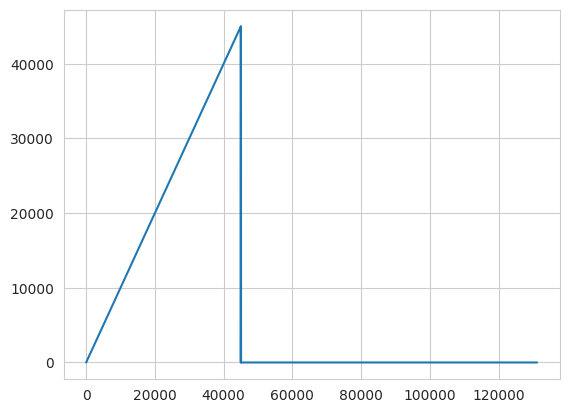

In [76]:
plt.plot(datas[8])

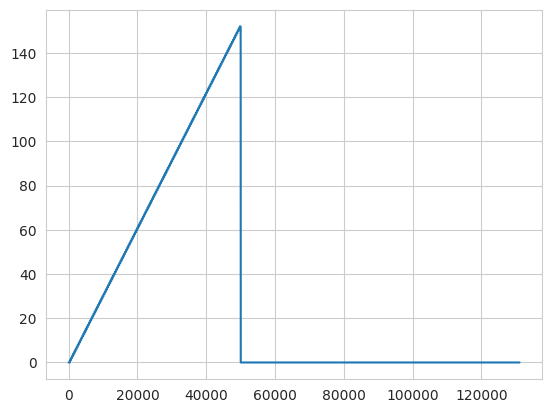

In [77]:
plt.plot(datas[13])

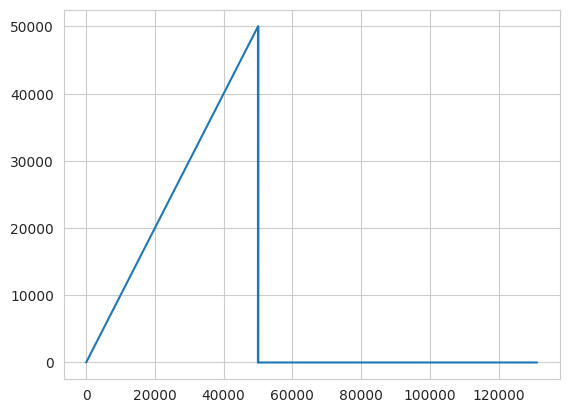

In [78]:
plt.plot(datas[18])

In [79]:
tables = list()
for raw_file in raw_files:
	print('================ FILENAME', raw_file.filename)
	tables.append(raw_file['df_with_missing/table'][:])

================ FILENAME /home/julian-zim/Desktop/DATA/fly-2023-schaffner/markers/2019_06_26_fly2.h5
================ FILENAME /home/julian-zim/Desktop/DATA/fly-2023-schaffner/markers/2019_08_07_fly2.h5


In [80]:
table_dfs = list()
for table in tables:
	data = [t[1] for t in table]
	table_dfs.append(pd.DataFrame(np.array(data)))

In [81]:
c = 0
columns = list()
for i in range(24):
	if (i+1) % 3 != 0:
		columns.append(f'Marker{c}')
		c += 1
	else:
		columns.append('drop')

table_df_filtered = list()
for table in table_dfs:
	table.columns = columns
	table_df_filtered.append(table.drop("drop", axis=1))

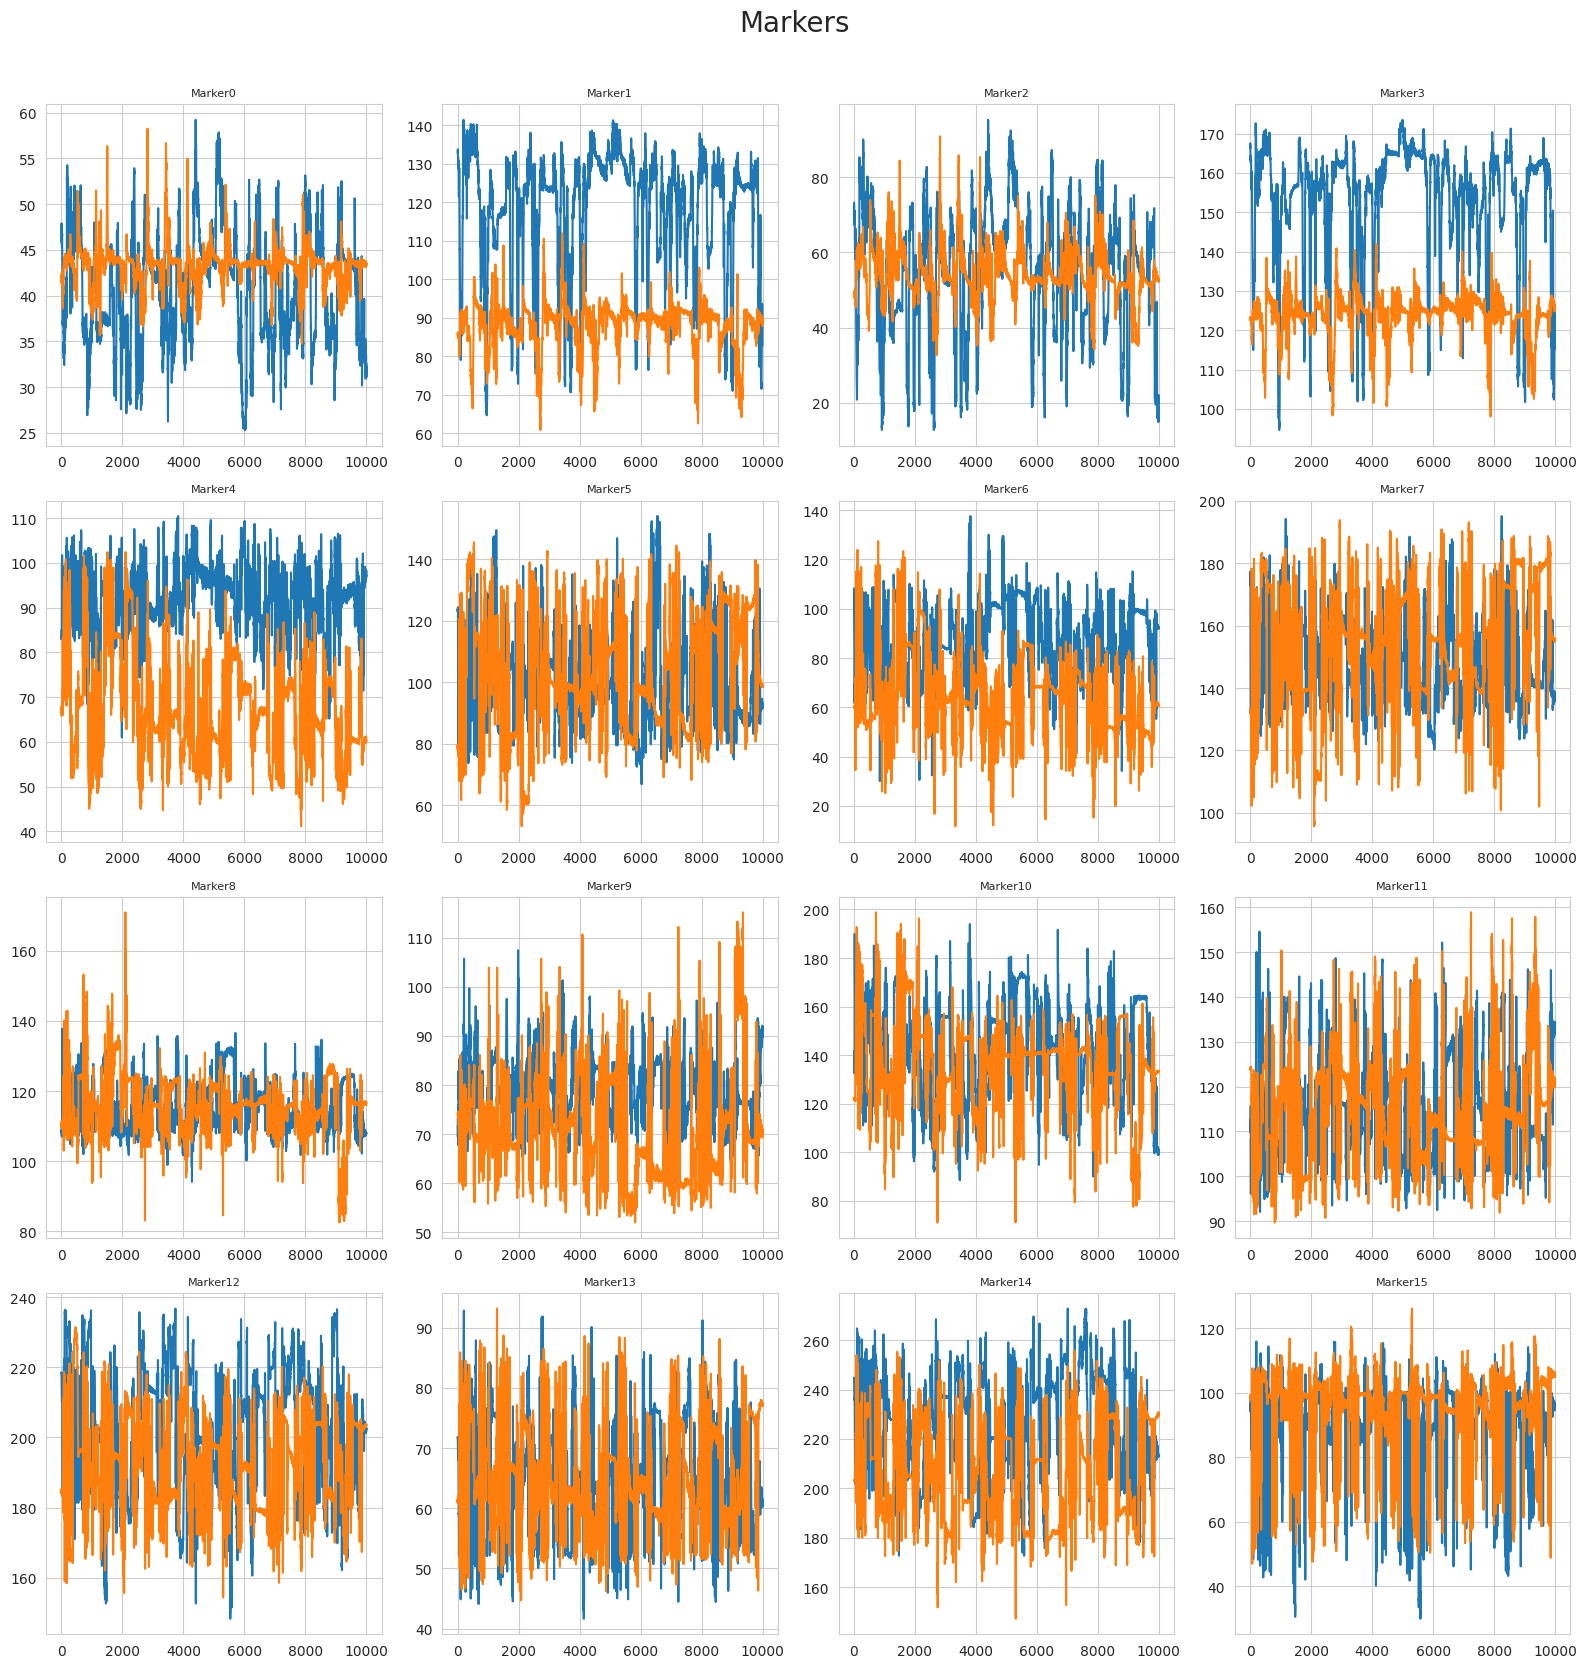

In [82]:
plot_utils.subplot('Markers', [t.loc[:10000] for t in table_df_filtered])